# Context

We have made a significant number of changes to the optimization algorithm since we last compared it against the previous `mGST`. In our last excursion, we implemented a linearized version of the algorithm that speed up the computation in addition to (finally) carrying over the radius, helping us avoid getting stuck in obvious local minima.

Both of those improvements made a difference in their own domain. The next goal would be to address the phase transition for 1Q with rank 2 and 2Q with rank 4, 16. However, first, I think is good to check if the optimization in itself is at least as good as the previous mGST one. In other words, whether we are getting stuck again in a (yet again) obvious local minima.

# GOAL:

Compare the performance of mGST on a single qubit GST with full rank and find that we at least as good in both time and performance.

In [65]:
%load_ext autoreload
%autoreload 2

import jax
jax.config.update("jax_enable_x64", True)

from mGST.low_level_jit import cost_function_jax_mps
from mGST.utility_functions_comparisons import GSTConfiguration, get_full_mgst_parameters_from_configuration, get_compressed_rep_from_mgst_output, get_initial_gate_set_for_optimization
from mGST.trust_region import run_riemannian_optimization
from mGST.typing import OperatorSchedule, TrustRegionOptions
from mGST.visualization import plot_cost_function
from mGST.additional_fns import perturbed_target_init

from mGST.algorithm import run_mGST, objf
import jax.numpy as jnp
import numpy as np

backend = "iqmfakeapollo"

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Data generation

In [3]:
dim_1q = 2
num_circuits_1q = 100
num_shots = 1000
kraus_rank = 4
num_povm = dim_1q # full

Q1_GST = GSTConfiguration(
    qubit_layouts=[[0]],
    gate_set="1QXYI",
    num_circuits=num_circuits_1q,
    shots=num_shots,
    rank=kraus_rank,
)

kraus_tensor_mgst_1q, kraus_mgst_1q, povm_mgst_1q, state_mgst_1q, prob_matrix_1q, indices_list_1q, additional_mgst_vars = get_full_mgst_parameters_from_configuration(
    Q1_GST, backend, only_jax_variables=False
)

kraus_tensor_1q_target, povm_psd_1q_target, state_psd_1q_target = get_compressed_rep_from_mgst_output(kraus_mgst_1q, povm_mgst_1q, state_mgst_1q, kraus_rank=kraus_rank, state_rank=dim_1q, povm_rank=dim_1q)

2026-09-28 16:12:00,206 - iqm.benchmarks.logging_config - INFO - Generating 100 random GST circuits
2026-09-28 16:12:00,237 - iqm.benchmarks.logging_config - INFO - Will transpile all 100 circuits according to fixed physical layout
2026-09-28 16:12:00,266 - iqm.benchmarks.logging_config - INFO - Transpiling for backend IQMFakeApolloBackend with optimization level 0, sabre routing method all circuits
2026-09-28 16:12:00,732 - iqm.benchmarks.logging_config - INFO - Submitting batch with 100 circuits corresponding to qubits [0]
2026-09-28 16:12:00,733 - iqm.benchmarks.logging_config - INFO - Stored jobs for 1 layouts in dataset
2026-09-28 16:12:00,788 - iqm.benchmarks.logging_config - INFO - Now executing the corresponding circuit batch
2026-09-28 16:12:00,965 - iqm.benchmarks.logging_config - INFO - Retrieving all counts
2026-09-28 16:12:00,966 - iqm.benchmarks.logging_config - INFO - Adding counts to dataset
2026-09-28 16:12:01,072 - iqm.benchmarks.logging_config - INFO - Run completed


In [18]:
target_gate_set_psd = {
    "kraus": kraus_tensor_1q_target,
    "povm": povm_psd_1q_target,
    "state": state_psd_1q_target,
}

In [5]:
state_rank = dim_1q # max
povm_rank = dim_1q # max

target_gate_set_superops = {
    "kraus": kraus_mgst_1q,
    "povm": povm_mgst_1q,
    "state": state_mgst_1q
}


# 2. Initiallization
init_gate_set_psd = get_initial_gate_set_for_optimization(
    target_superops=target_gate_set_superops,
    kraus_rank=kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank
)

cost_fn_kwargs = {
    "indices_list": indices_list_1q,
    "prob_matrix": prob_matrix_1q,
    "jit": True,
    "use_log_likelihood": True,
    "verbose": False,  # we don't want to print during the cost function evaluation
    "num_shots": num_shots,
}

# Test cost functions

In [7]:
initial_cost_jax_log_likelihood = cost_function_jax_mps(*init_gate_set_psd.values(), **cost_fn_kwargs)
print("Initial cost (JAX - log likelihood):", initial_cost_jax_log_likelihood)

initial_cost_jax_least_squares = cost_function_jax_mps(*init_gate_set_psd.values(), **{**cost_fn_kwargs, "use_log_likelihood": False})
print("Initial cost (JAX - least squares):", initial_cost_jax_least_squares)

Initial cost (JAX - log likelihood): 56656.930231728154
Initial cost (JAX - least squares): 0.0037819854474798386


In [19]:
initial_cost_jax_least_squares_target = cost_function_jax_mps(*target_gate_set_psd.values(), **{**cost_fn_kwargs, "use_log_likelihood": False})
print(initial_cost_jax_least_squares_target)

0.0019018358155592511


In [13]:
initial_gate_set_mgst = {op_name: np.array(op) for op_name, op in target_gate_set_superops.items()}

In [23]:
initial_cost_mgst_least_squares = objf(*initial_gate_set_mgst.values(), J=additional_mgst_vars["J"], y=prob_matrix_1q, mle=False)
print("Initial cost (MGST - least squares):", initial_cost_mgst_least_squares)

Initial cost (MGST - least squares): 0.0019018358155592665


In [24]:
initial_cost_mgst_log_likelihood = objf(*initial_gate_set_mgst.values(), J=additional_mgst_vars["J"], y=prob_matrix_1q, mle=True)
print("Initial cost (MGST - log likelihood):", initial_cost_mgst_log_likelihood)

Initial cost (MGST - log likelihood): inf


In [22]:
jnp.allclose(initial_cost_jax_least_squares_target, initial_cost_mgst_least_squares)

Array(True, dtype=bool)

For the least squares they are the same. Log likelihood from mGST is not behaving too well but not sure why?

# Optimization

In [160]:
num_iterations_outer = 20
num_iterations_tr = 5
num_iterations_cg = 10 
tol_grad = 1e-8 # it was 1e-4 before. 1e-8 is suggested in the book.
relative_precision = 1e-8 # changing to the default value of mGST.
global_gradient_norm_tol = 1e-10

tr_schedule_no_linearize = OperatorSchedule.default(num_iterations_outer, TrustRegionOptions(num_iterations=num_iterations_tr, verbose=True, verbose_cg=True, num_iterations_cg=num_iterations_cg, tol_grad=tol_grad, linearize=False))

tr_schedule_povm_state = OperatorSchedule.default(num_iterations_outer, TrustRegionOptions(num_iterations=num_iterations_tr, verbose=True, verbose_cg=True, num_iterations_cg=num_iterations_cg, tol_grad=tol_grad, linearize=True, radius_init=1e-4))

tr_schedule_linearized = OperatorSchedule.default(num_iterations_outer, TrustRegionOptions(num_iterations=num_iterations_tr, verbose=True, verbose_cg=True, num_iterations_cg=num_iterations_cg, tol_grad=tol_grad, linearize=True))

optimization_schedule_only_kraus_linearized_og_radius = {
    "kraus": tr_schedule_linearized,
    "povm": tr_schedule_no_linearize,
    "state": tr_schedule_no_linearize
}

optimization_options = {
    "optimization_schedule": optimization_schedule_only_kraus_linearized_og_radius,
    "num_iterations": num_iterations_outer,
    "relative_precision": relative_precision,
    "global_gradient_norm_tol": global_gradient_norm_tol,
    "noise_threshold": None,
    "compute_least_squares": 1,
    "carry_over_radius": True,
}

In [ ]:
optimization_schedule_all_linearized_smaller_radius = {
    "kraus": tr_schedule_linearized,
    "povm": tr_schedule_povm_state,
    "state": tr_schedule_povm_state
}

optimization_options_rel_1e_3 = {
    "optimization_schedule": optimization_schedule_all_linearized_smaller_radius,
    "num_iterations": num_iterations_outer,
    "relative_precision": 1e-3, # changed due to the changes in convergence criteria
    "global_gradient_norm_tol": global_gradient_norm_tol,
    "noise_threshold": None,
    "compute_least_squares": 1,
    "carry_over_radius": True,
}

In [176]:
optimization_options_og_radius_kraus_linearized = {
    "optimization_schedule": optimization_schedule_only_kraus_linearized_og_radius,
    "num_iterations": num_iterations_outer,
    "relative_precision": 1e-3, # changed due to the changes in convergence criteria
    "global_gradient_norm_tol": global_gradient_norm_tol,
    "noise_threshold": None,
    "compute_least_squares": 1,
    "carry_over_radius": True,
}

In [186]:
optimized_operators_jax_rel_1e_3_projected, cost_fn_history_jax_rel_1e_3_projected, convergence_reason_jax_rel_1e_3_projected = run_riemannian_optimization(
    *init_gate_set_psd.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    verbose=True,
    **optimization_options_rel_1e_3,
)

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
kraus: Schedule:
  [0-19]: TrustRegionOptions
povm: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Gradient(s) Norm(s) 📐
 * cost floor: 5.348103e+04
🚀 TR started for operator: povm 🚀.
TR Iteration: 0. f(x): 5.665693e+04. |r∇f(x)|: 5.000000e+08. Radius: 1.00e-04
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
Update rejected ❌. Quality quotient: 1.312437e-02 < 1.250000e-01
TR Iteration: 1. f(x): 5.665693e+04. |r∇f(x)|: 5.000000e+08. Radius: 2.50e-05
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
Update rejected ❌. Quality quotient: 4.143110e-02 < 1.250000e-01
TR Iteration: 2. f(x): 5.6656

In [182]:
optimized_operators_jax_rel_1e_3, cost_fn_history_jax_rel_1e_3, convergence_reason_jax_rel_1e_3 = run_riemannian_optimization(
    *init_gate_set_psd.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    verbose=True,
    **optimization_options_rel_1e_3,
)

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
kraus: Schedule:
  [0-19]: TrustRegionOptions
povm: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Gradient(s) Norm(s) 📐
 * cost floor: 5.348103e+04
🚀 TR started for operator: povm 🚀.
TR Iteration: 0. f(x): 5.665693e+04. |r∇f(x)|: 5.000000e+08. Radius: 1.00e-04
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
Update rejected ❌. Quality quotient: 1.312437e-02 < 1.250000e-01
TR Iteration: 1. f(x): 5.665693e+04. |r∇f(x)|: 5.000000e+08. Radius: 2.50e-05
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
Update rejected ❌. Quality quotient: 4.143110e-02 < 1.250000e-01
TR Iteration: 2. f(x): 5.6656

In [188]:
optimized_operators_jax_og_radius_kraus_linearized_projected, cost_fn_history_jax_og_radius_kraus_linearized_projected, convergence_reason_jax_og_radius_kraus_linearized_projected = run_riemannian_optimization(
    *init_gate_set_psd.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    verbose=True,
    **optimization_options_og_radius_kraus_linearized,
)

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
kraus: Schedule:
  [0-19]: TrustRegionOptions
povm: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Gradient(s) Norm(s) 📐
 * cost floor: 5.348103e+04
🚀 TR started for operator: povm 🚀.
TR Iteration: 0. f(x): 5.665693e+04. |r∇f(x)|: 5.000000e+08. Radius: 1.00e-01
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
Update rejected ❌. Quality quotient: 3.223233e-05 < 1.250000e-01
TR Iteration: 1. f(x): 5.665693e+04. |r∇f(x)|: 5.000000e+08. Radius: 2.50e-02
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
Update rejected ❌. Quality quotient: 9.882273e-05 < 1.250000e-01
TR Iteration: 2. f(x): 5.6656

In [195]:
optimized_operators_jax_abs_tol, cost_fn_history_jax_abs_tol, convergence_reason_jax_abs_tol = run_riemannian_optimization(
    *init_gate_set_psd.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    verbose=True,
    absolute_tolerance=1,
    **optimization_options_rel_1e_3,
)

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
kraus: Schedule:
  [0-19]: TrustRegionOptions
povm: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Absolute Tolerance 📉 1.00e+00 
+ Gradient(s) Norm(s) 📐
 * cost floor: 5.348103e+04
🚀 TR started for operator: povm 🚀.
TR Iteration: 0. f(x): 5.665693e+04. |r∇f(x)|: 5.000000e+08. Radius: 1.00e-04
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
Update rejected ❌. Quality quotient: 1.312437e-02 < 1.250000e-01
TR Iteration: 1. f(x): 5.665693e+04. |r∇f(x)|: 5.000000e+08. Radius: 2.50e-05
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
Update rejected ❌. Quality quotient: 4.143110e-02 < 1.250000e

In [196]:
optimized_operators_jax_abs_tol_jitted, cost_fn_history_jax_abs_tol_jitted, convergence_reason_jax_abs_tol_jitted = run_riemannian_optimization(
    *init_gate_set_psd.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    verbose=True,
    absolute_tolerance=1,
    use_jit=True,
    jit_contraction="prefix",
    **optimization_options_rel_1e_3,
)

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
kraus: Schedule:
  [0-19]: TrustRegionOptions
povm: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Absolute Tolerance 📉 1.00e+00 
+ Gradient(s) Norm(s) 📐
 * cost floor: 5.348103e+04
 * jitted objective: yes (prefix contraction)
🚀 TR started for operator: povm 🚀.
TR Iteration: 0. f(x): 5.665693e+04. |r∇f(x)|: 5.000000e+08. Radius: 1.00e-04
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
Update rejected ❌. Quality quotient: 1.312437e-02 < 1.250000e-01
TR Iteration: 1. f(x): 5.665693e+04. |r∇f(x)|: 5.000000e+08. Radius: 2.50e-05
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
Update rejected

In [180]:
optimized_operators_jax_og_radius_kraus_linearized, cost_fn_history_jax_og_radius_kraus_linearized, convergence_reason_jax_og_radius_kraus_linearized = run_riemannian_optimization(
    *init_gate_set_psd.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    verbose=True,
    **optimization_options_og_radius_kraus_linearized,
)

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
kraus: Schedule:
  [0-19]: TrustRegionOptions
povm: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Gradient(s) Norm(s) 📐
 * cost floor: 5.348103e+04
🚀 TR started for operator: povm 🚀.
TR Iteration: 0. f(x): 5.665693e+04. |r∇f(x)|: 5.000000e+08. Radius: 1.00e-01
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
Update rejected ❌. Quality quotient: 3.223233e-05 < 1.250000e-01
TR Iteration: 1. f(x): 5.665693e+04. |r∇f(x)|: 5.000000e+08. Radius: 2.50e-02
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
Update rejected ❌. Quality quotient: 9.882273e-05 < 1.250000e-01
TR Iteration: 2. f(x): 5.6656

In [175]:
[(i, prob_matrix_1q[:, i]) for i, s in enumerate(indices_list_1q) if len(s) == 0]

[(0, array([0.95, 0.05]))]

In [ ]:
optimized_operators_jax, cost_fn_history_jax, convergence_reason_jax = run_riemannian_optimization(
    *init_gate_set_psd.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    verbose=True,
    **optimization_options,
)

🔰 Starting Riemannian Optimization 🔰
🚀 TR started for operator: povm 🚀.
TR Iteration: 0. f(x): 5.665693e+04. |r∇f(x)|: 5.000000e+08. Radius: 1.00e-01
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
Update rejected ❌. Quality quotient: 3.223233e-05 < 1.250000e-01
TR Iteration: 1. f(x): 5.665693e+04. |r∇f(x)|: 5.000000e+08. Radius: 2.50e-02
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
Update rejected ❌. Quality quotient: 9.882273e-05 < 1.250000e-01
TR Iteration: 2. f(x): 5.665693e+04. |r∇f(x)|: 5.000000e+08. Radius: 6.25e-03
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
Update rejected ❌. Quality quotient: 3.428519e-04 < 1.250000e-01
TR Iteration: 3. f(x): 5.665693e+04. |r∇f(x)|: 5.000000e+08. Radius: 1.56e-03
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 

In [ ]:
# measurement_samples (y), indices_list (J), None, number of gates in gate set (d), physical dimension squares (r), kraus rank (rK), num_povm elements, size of batches (not used here but still expected), number of shots (meas_samples)
num_gates = 3
mgst_args = [prob_matrix_1q, additional_mgst_vars["J"], None, num_gates, dim_1q**2, kraus_rank, num_povm, additional_mgst_vars["bsize"], num_shots] 

kraus_init_mgst = perturbed_target_init(initial_gate_set_mgst["kraus"], kraus_rank, seed=42)
init_ops_mgst = [kraus_init_mgst, initial_gate_set_mgst["povm"], initial_gate_set_mgst["state"]]

In [166]:
mgst_max_iters = 80
mgst_target_rel_prec = 1e-8

2026-10-01 11:11:05,209 - iqm.benchmarks.logging_config - INFO - Starting mGST optimization...
100%|██████████| 80/80 [01:52<00:00,  1.41s/it]


Reached maximum iterations (80) without convergence.


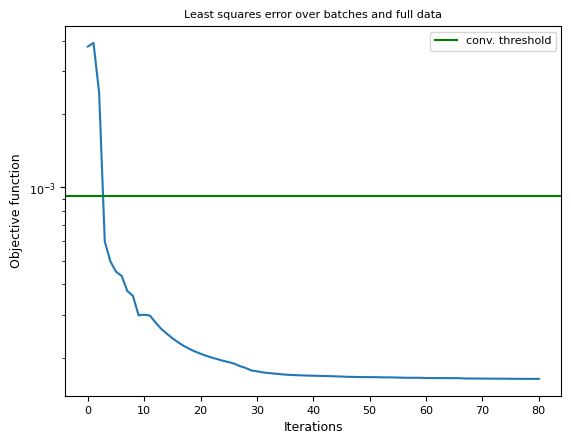

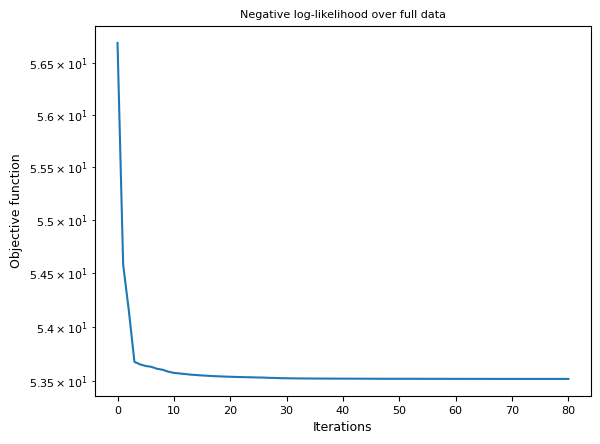

2026-10-01 11:12:58,260 - iqm.benchmarks.logging_config - INFO - Convergence criterion satisfied
2026-10-01 11:12:58,261 - iqm.benchmarks.logging_config - INFO - Final objective 1.64e-4 in time 113.05s


In [168]:
*optimized_operators_mgst, cost_fn_history_mgst = run_mGST(
    *mgst_args,
    init = init_ops_mgst,
    method = "SFN",
    final_iter=mgst_max_iters,
    target_rel_prec=mgst_target_rel_prec,
    return_operators_list=False,
    verbose_level=2,
    use_log_likelihood=True
)

In [68]:
cost_fn_history_mgst.keys()

dict_keys(['log_likelihood', 'least_squares'])

In [190]:
title_init = rf"1Q | $r_\mathrm{{Kraus}}$: {kraus_rank} | $r_\mathrm{{POVM}}$: {povm_rank} | $r_\mathrm{{State}}$: {state_rank} | Shots: {num_shots} | Num. Sequences: {num_circuits_1q}"

cost_fns = [cost_fn_history_jax, cost_fn_history_mgst, cost_fn_history_jax_rel_1e_3]

labels = [f"JAX (with bug) (2 min 39.7s)\n relative precision: {relative_precision}", f"mGST (2 mins 39.7s) \n relative precision: {mgst_target_rel_prec}", f"JAX (6 mins 59s)\n relative precision: {1e-3:.1e}"]

In [115]:
mgst_loglikelihood = cost_fn_history_mgst["log_likelihood"]
jnp.abs(mgst_loglikelihood[-1] - mgst_loglikelihood[-2])/mgst_loglikelihood[-2]

Array(1.34153591e-06, dtype=float64, weak_type=True)

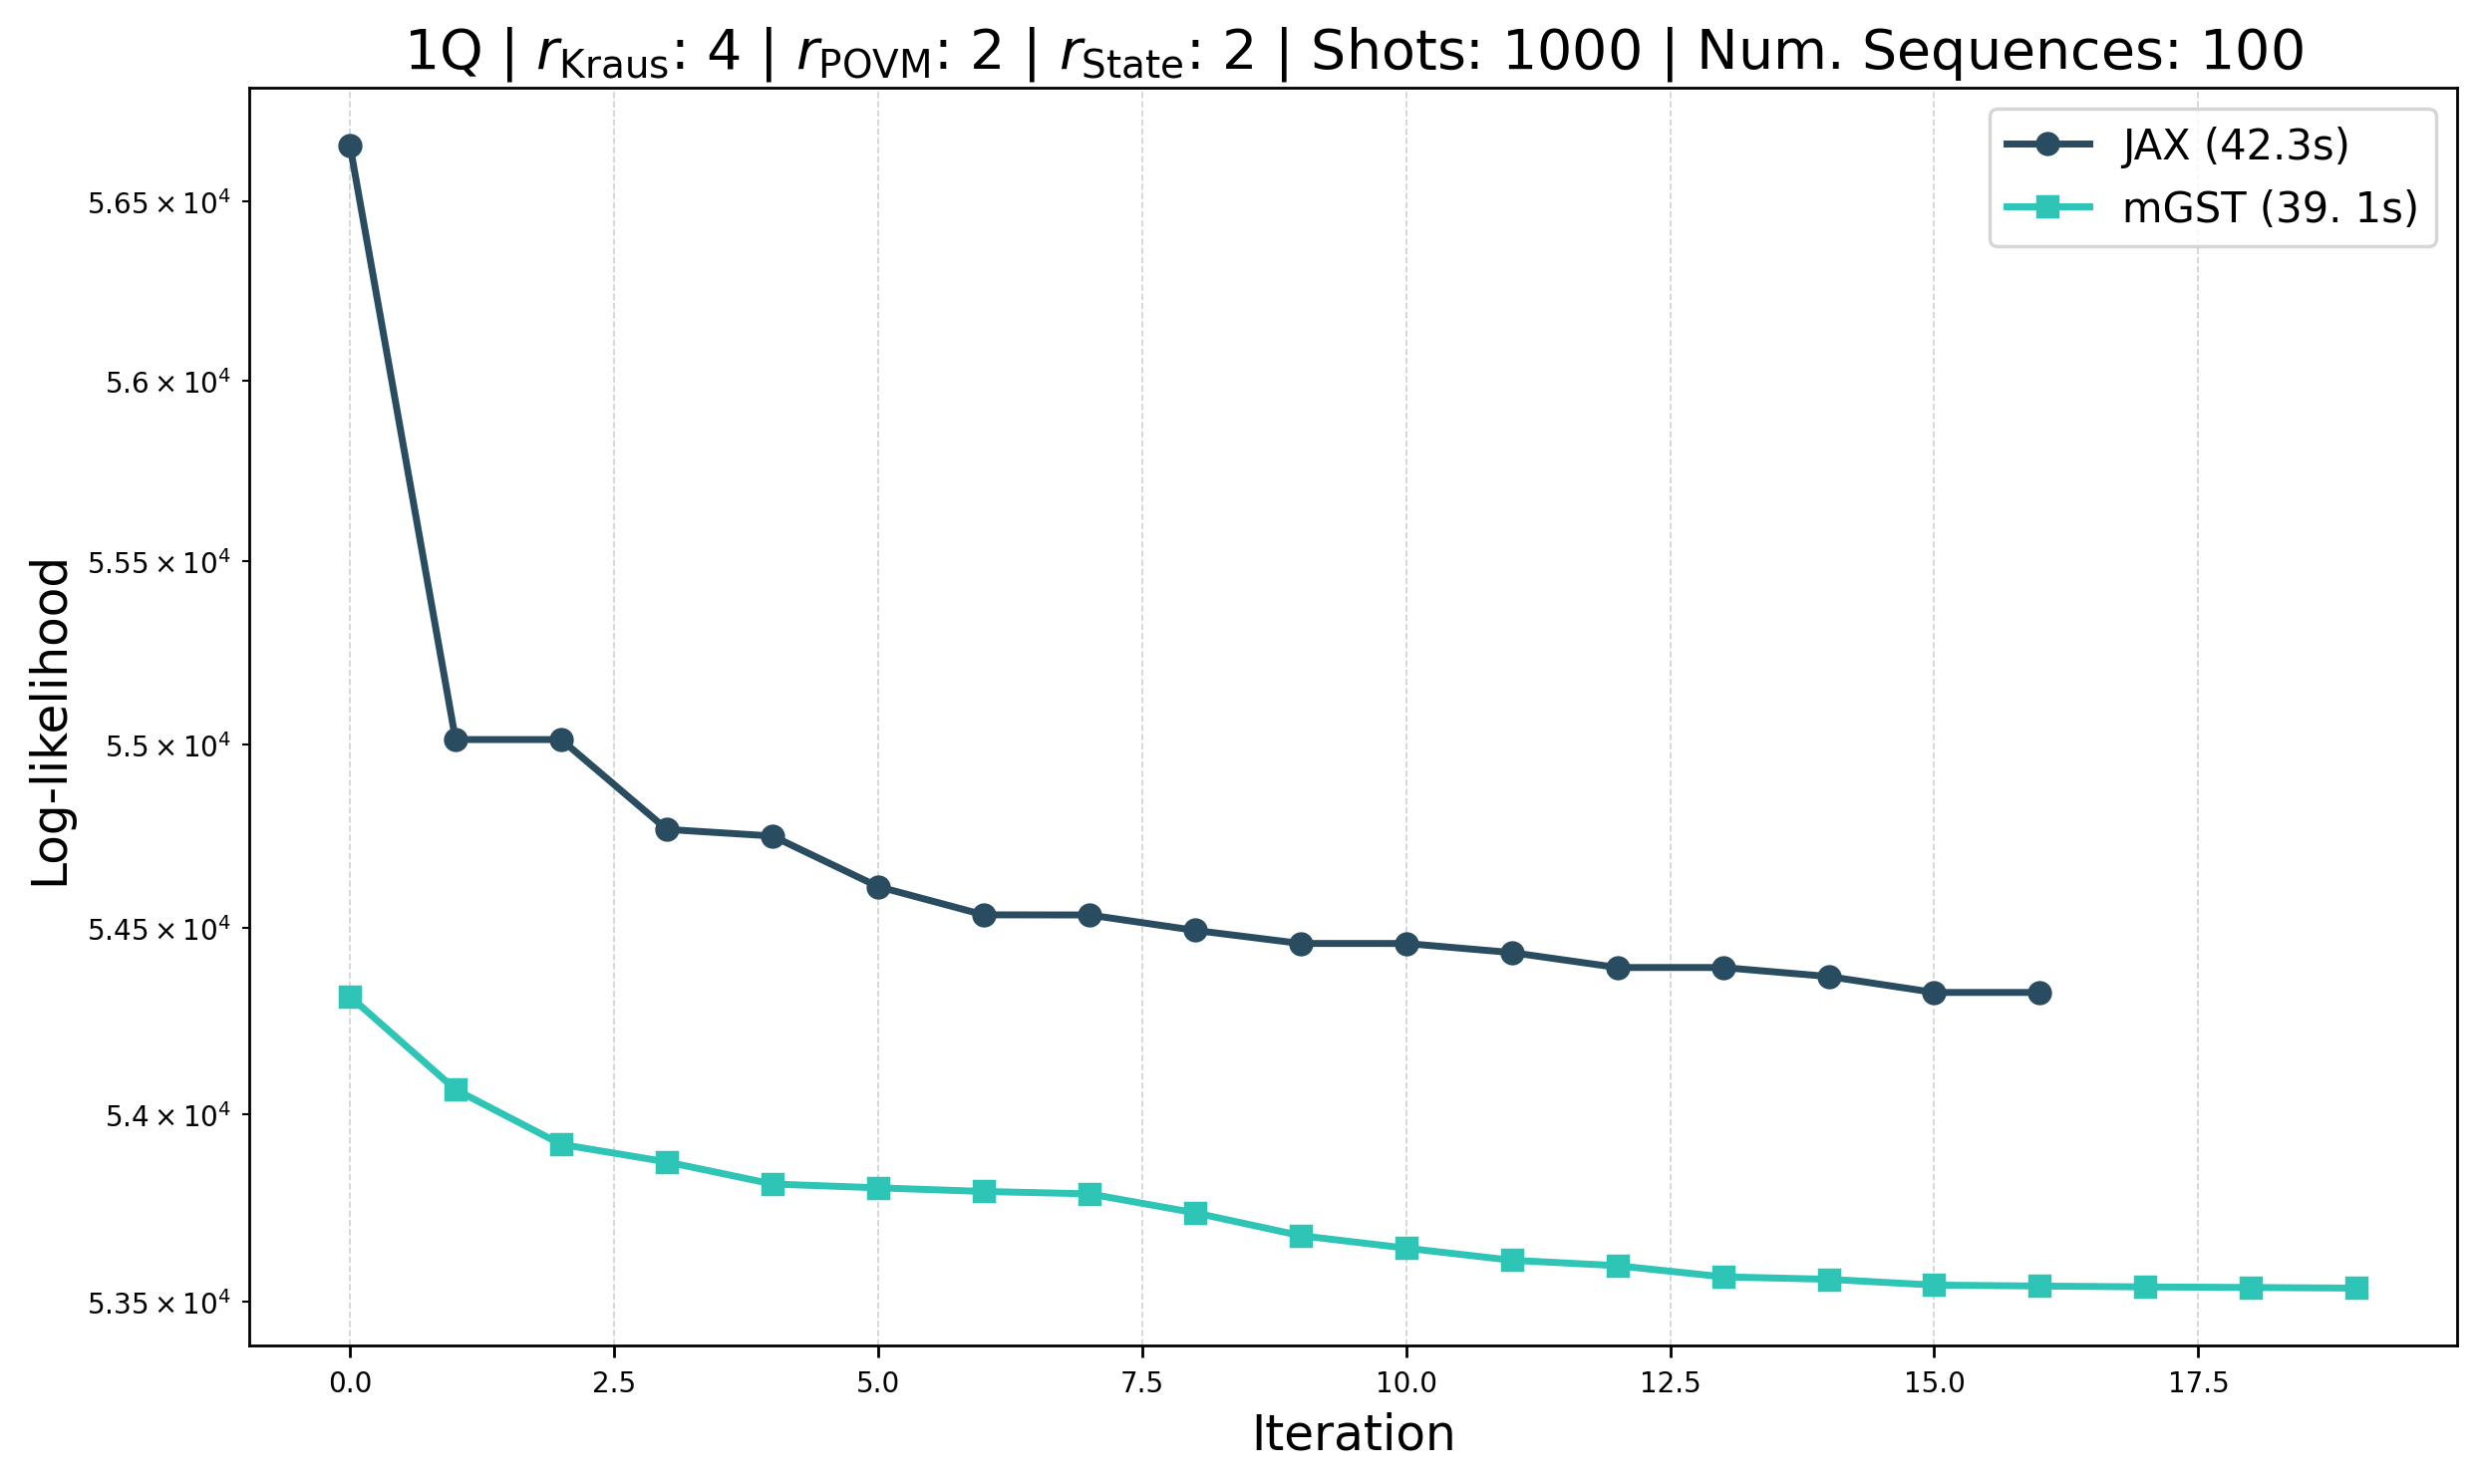

In [ ]:
# cost_fns_log_likelihood = [cost["main"] for cost in cost_fns]
# Previous shorter one for both.
# cost_fns_log_likelihood = [cost_fn_history_jax["main"], jnp.array(cost_fn_history_mgst["log_likelihood"])*num_shots]

# plot_cost_function(cost_fns_log_likelihood, title=title_init, labels=labels, ylabel="Log-likelihood") 

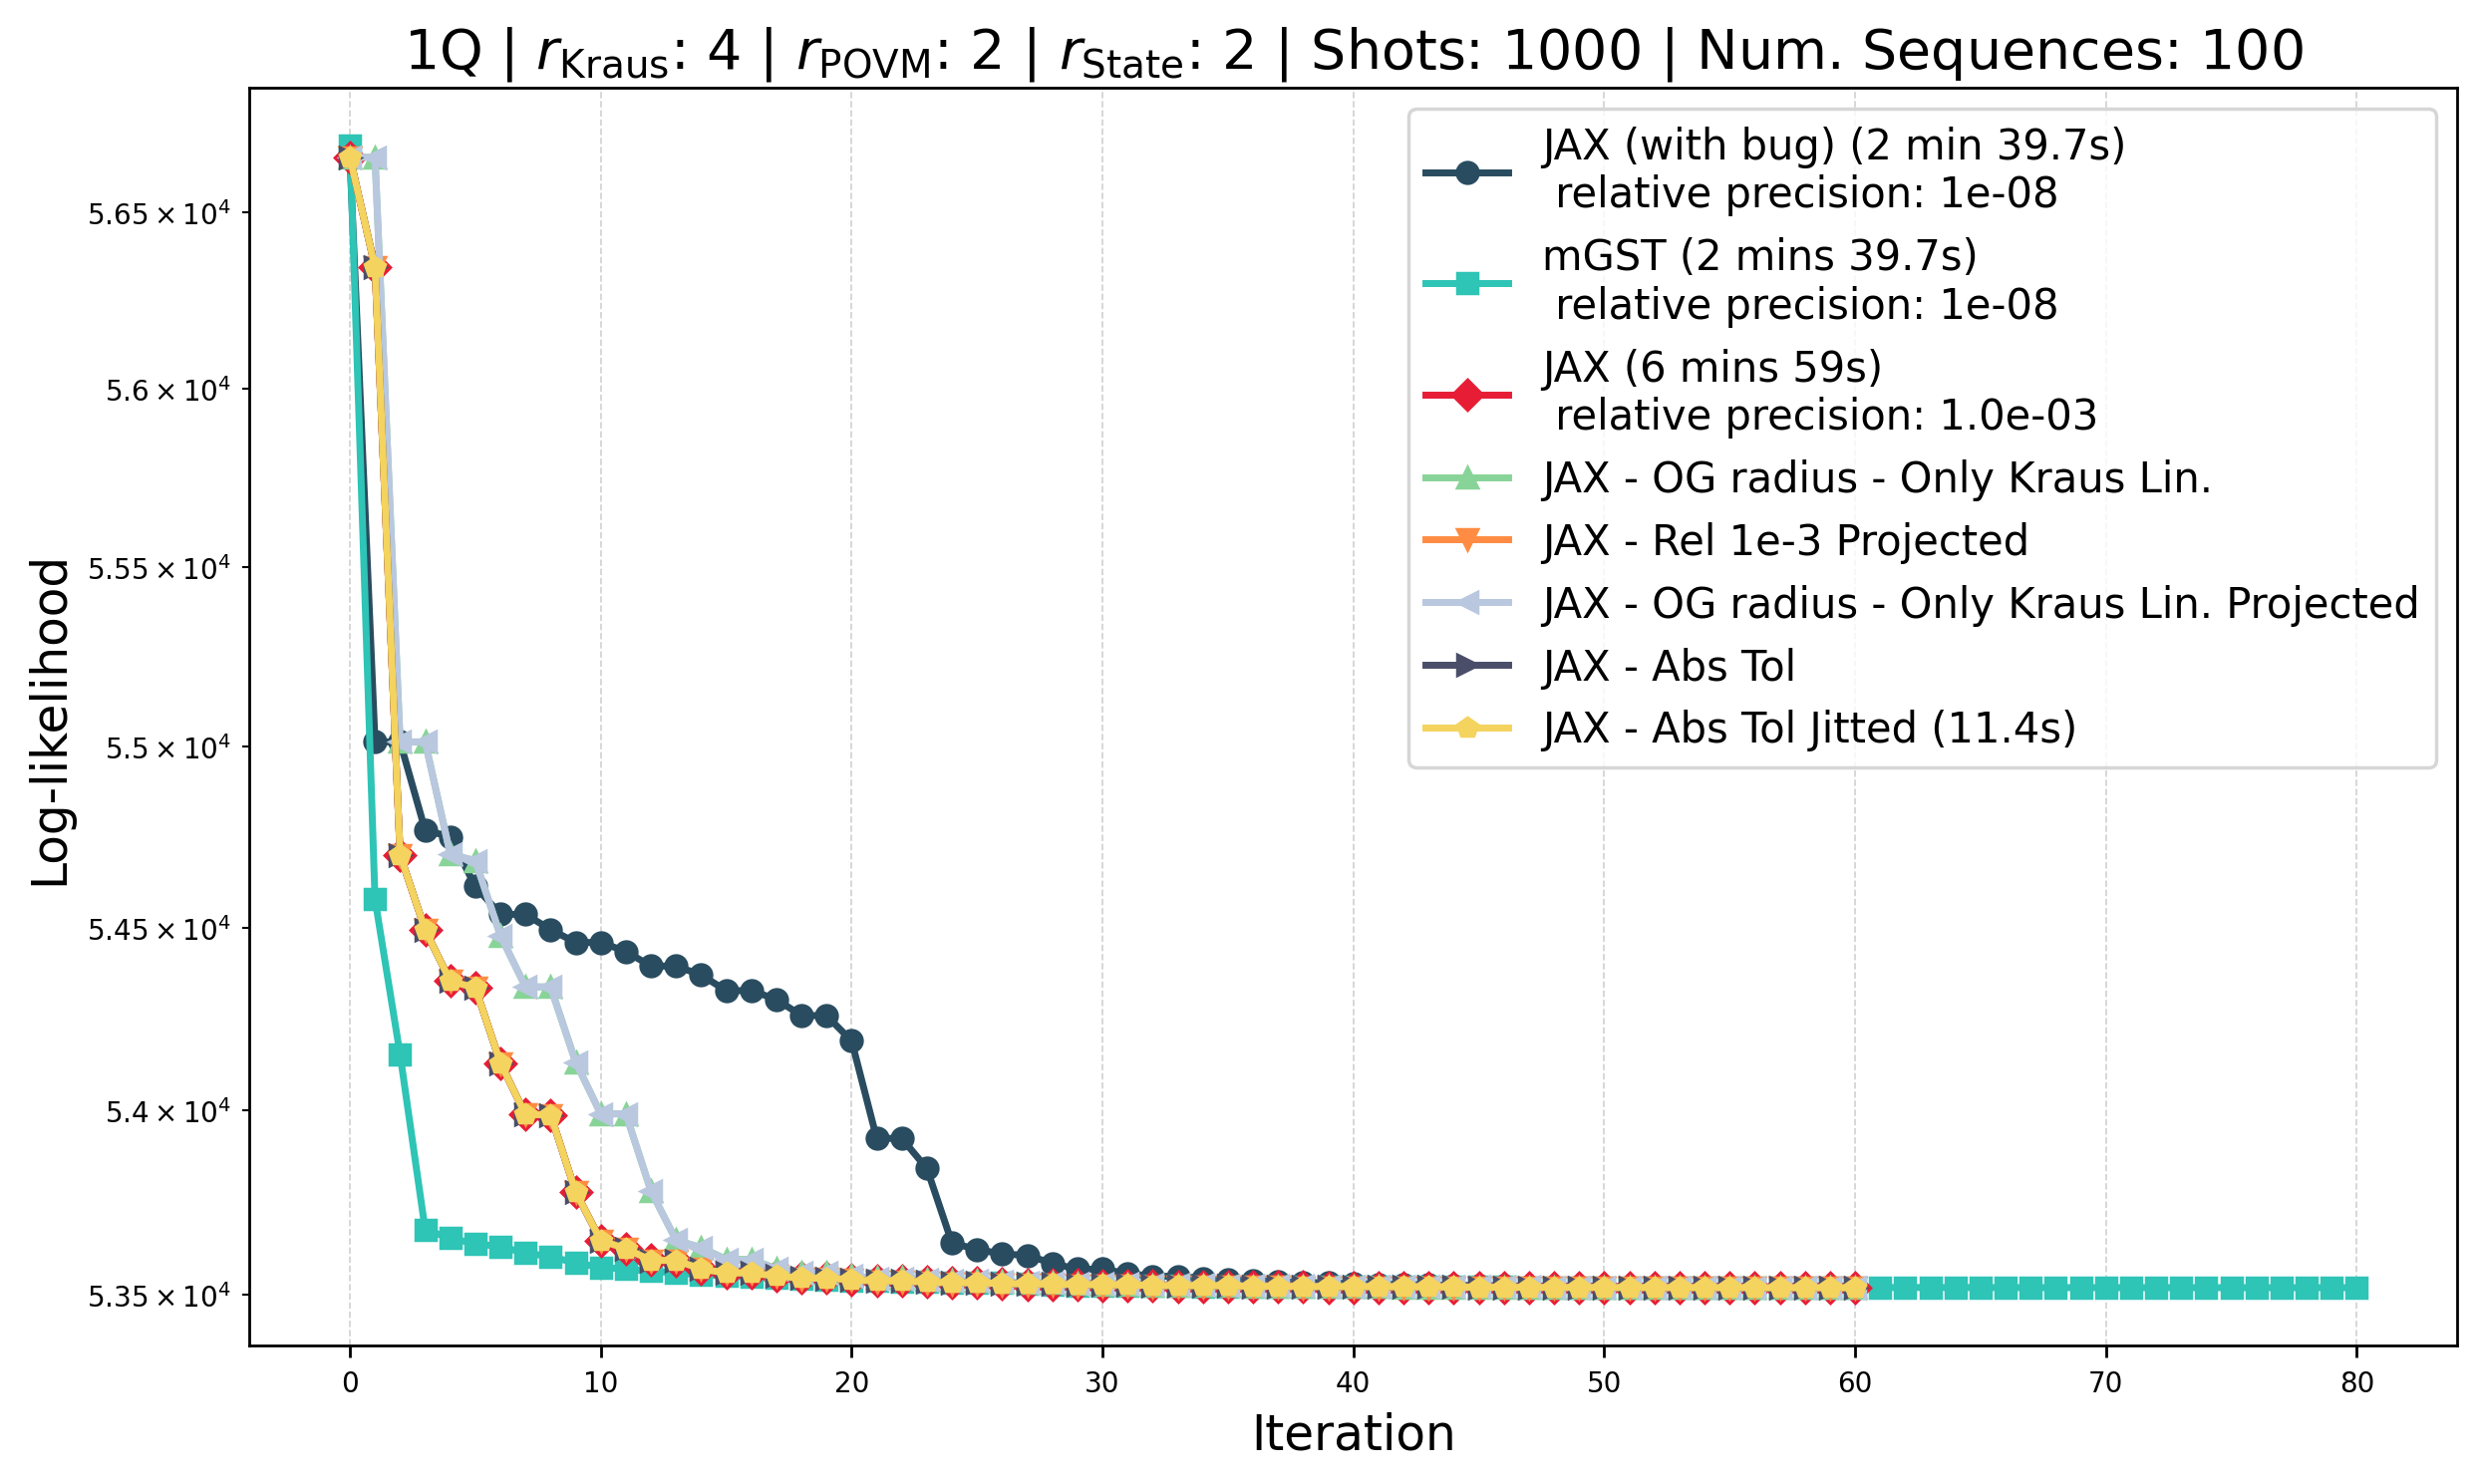

In [198]:
cost_fns_log_likelihood = [cost_fn_history_jax["main"], jnp.array(cost_fn_history_mgst["log_likelihood"])*num_shots, cost_fn_history_jax_rel_1e_3["main"], cost_fn_history_jax_og_radius_kraus_linearized["main"], cost_fn_history_jax_rel_1e_3_projected["main"], cost_fn_history_jax_og_radius_kraus_linearized_projected["main"], cost_fn_history_jax_abs_tol["main"], cost_fn_history_jax_abs_tol_jitted["main"]] 

labels_extended = labels + ["JAX - OG radius - Only Kraus Lin.", "JAX - Rel 1e-3 Projected", "JAX - OG radius - Only Kraus Lin. Projected", "JAX - Abs Tol", "JAX - Abs Tol Jitted (11.4s)"]

plot_cost_function(cost_fns_log_likelihood, title=title_init, labels=labels_extended, ylabel="Log-likelihood") 

In [165]:
cost_fn_history_jax_rel_1e_3

{'main': [Array(56656.93023173, dtype=float64),
  Array(56344.1877349, dtype=float64),
  Array(54707.44118086, dtype=float64),
  Array(54501.47703259, dtype=float64),
  Array(54360.91673494, dtype=float64),
  Array(54335.85285951, dtype=float64),
  Array(54130.26239802, dtype=float64),
  Array(53989.3593621, dtype=float64),
  Array(53988.26193964, dtype=float64),
  Array(53778.88982248, dtype=float64),
  Array(53647.32434634, dtype=float64),
  Array(53626.13571395, dtype=float64),
  Array(53595.86926275, dtype=float64),
  Array(53595.56766268, dtype=float64),
  Array(53571.83122696, dtype=float64),
  Array(53560.50005653, dtype=float64),
  Array(53560.47504295, dtype=float64),
  Array(53551.88006692, dtype=float64),
  Array(53545.98880015, dtype=float64),
  Array(53545.86202236, dtype=float64),
  Array(53541.80600825, dtype=float64),
  Array(53538.16999527, dtype=float64),
  Array(53537.98897689, dtype=float64),
  Array(53535.65435147, dtype=float64),
  Array(53533.20366423, dtype=floa

In [155]:
iteration = 15
jnp.abs(cost_fn_history_jax["main"][iteration] - cost_fn_history_jax["main"][iteration+1])/cost_fn_history_jax["main"][iteration]

Array(3.30562773e-08, dtype=float64)

In [117]:
print(f"trust region optimization: {cost_fns_log_likelihood[0]}")

trust region optimization: [Array(56656.93023173, dtype=float64), Array(55012.27673143, dtype=float64), Array(55012.27673143, dtype=float64), Array(54767.88194006, dtype=float64), Array(54749.92058711, dtype=float64), Array(54612.88087832, dtype=float64), Array(54536.37707182, dtype=float64), Array(54536.11113059, dtype=float64), Array(54494.50255788, dtype=float64), Array(54459.11066417, dtype=float64), Array(54459.07330106, dtype=float64), Array(54434.53931602, dtype=float64), Array(54394.24001012, dtype=float64), Array(54394.23447103, dtype=float64), Array(54370.041153, dtype=float64), Array(54327.05551864, dtype=float64), Array(54327.05372279, dtype=float64), Array(54303.15771019, dtype=float64), Array(54258.77430361, dtype=float64), Array(54258.77313816, dtype=float64), Array(54189.50350859, dtype=float64), Array(53924.03675816, dtype=float64), Array(53924.03523459, dtype=float64), Array(53842.23773751, dtype=float64), Array(53640.65412754, dtype=float64), Array(53623.15285751, dt

In [118]:
print(f"saddle free newton optimization: {cost_fns_log_likelihood[1]}")

saddle free newton optimization: [56691.58759076 54316.4982018  54066.06060799 53919.67736589
 53872.68270151 53813.74497175 53803.57618346 53793.87072865
 53787.47326541 53736.87691184 53675.64807255 53642.27765374
 53610.62189005 53596.25112138 53566.9573636  53560.35730993
 53544.98767596 53542.36572678 53540.1026284  53538.56010363
 53536.77683225 53535.62849701 53534.14045066 53533.28081061
 53531.85948976 53531.20099863 53529.28970032 53528.78305854
 53525.94401647 53525.41227709 53525.21399318 53523.7368908
 53523.55884302 53523.47486664 53522.90105015 53522.81370327
 53522.68940297 53522.61425632 53522.09449539 53522.01361041
 53521.94180871]


In [119]:
jax_log_likelihood_init = cost_fns_log_likelihood[0][0]
mgst_log_likelihood_init = cost_fns_log_likelihood[1][0]
print(f"are they the same? {jnp.allclose(jax_log_likelihood_init, mgst_log_likelihood_init)}")
print(f"jax_log_likelihood_init: {jax_log_likelihood_init}")
print(f"mgst_log_likelihood_init: {mgst_log_likelihood_init}")

are they the same? False
jax_log_likelihood_init: 56656.930231728154
mgst_log_likelihood_init: 56691.58759075915


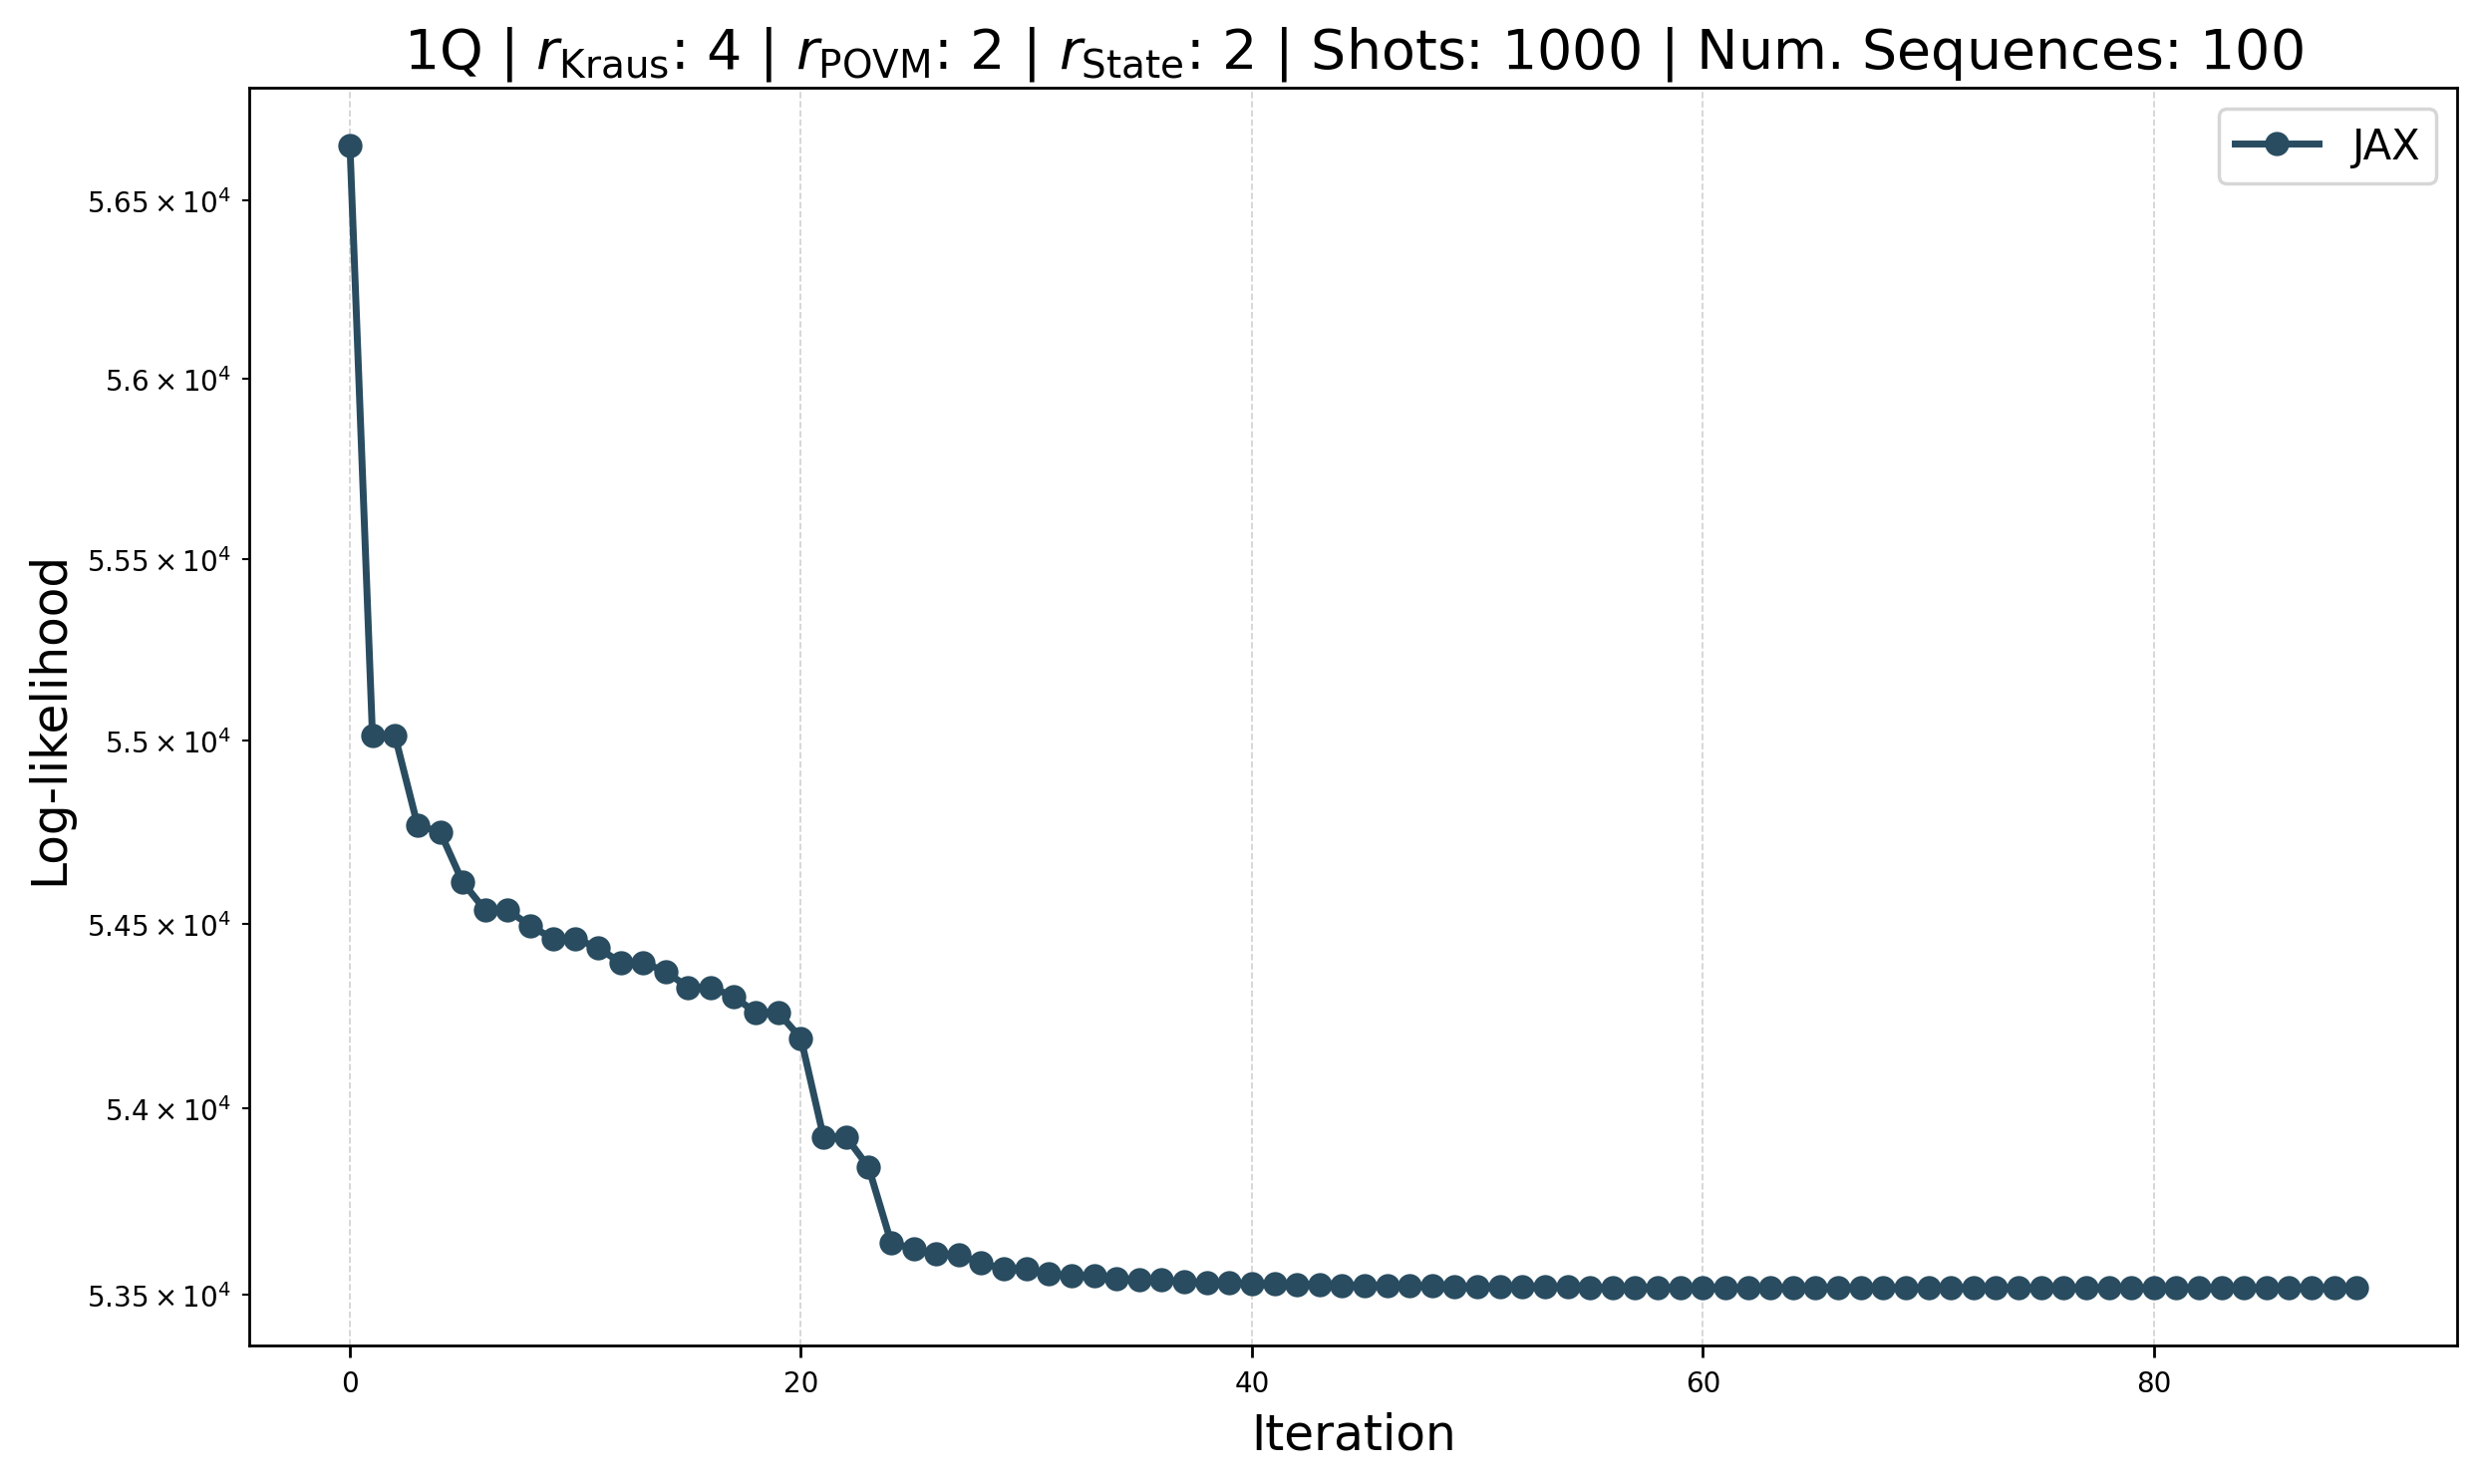

In [ ]:
# cost_fns_log_likelihood = [cost["main"] for cost in cost_fns]

# plot_cost_function(cost_fns_log_likelihood, title=title_init, labels=labels, ylabel="Log-likelihood") 

In [83]:
# # Waiting for 6<20 iterations with relative precision 1e-7
# final_value = cost_fn_history_jax["main"][-1]
# previous_value = cost_fn_history_jax["main"][-2]
# relative_change = jnp.abs(final_value - previous_value)
# relative_change/previous_value,  relative_precision

(Array(3.30562773e-08, dtype=float64), 1e-07)

In [89]:
# Waiting for 20 iterations with relative precision 1e-8
final_value = cost_fn_history_jax["main"][-1]
previous_value = cost_fn_history_jax["main"][-2]
relative_change = jnp.abs(final_value - previous_value)
relative_change/previous_value,  relative_precision

(Array(3.92664355e-06, dtype=float64), 1e-08)

In [41]:
# Waiting for 20 iterations with relative precision 1e-9
# final_value = cost_fn_history_jax["main"][-1]
# previous_value = cost_fn_history_jax["main"][-2]
# relative_change = jnp.abs(final_value - previous_value)
# relative_change/previous_value,  relative_precision

(Array(1.61674384e-07, dtype=float64), 1e-09)

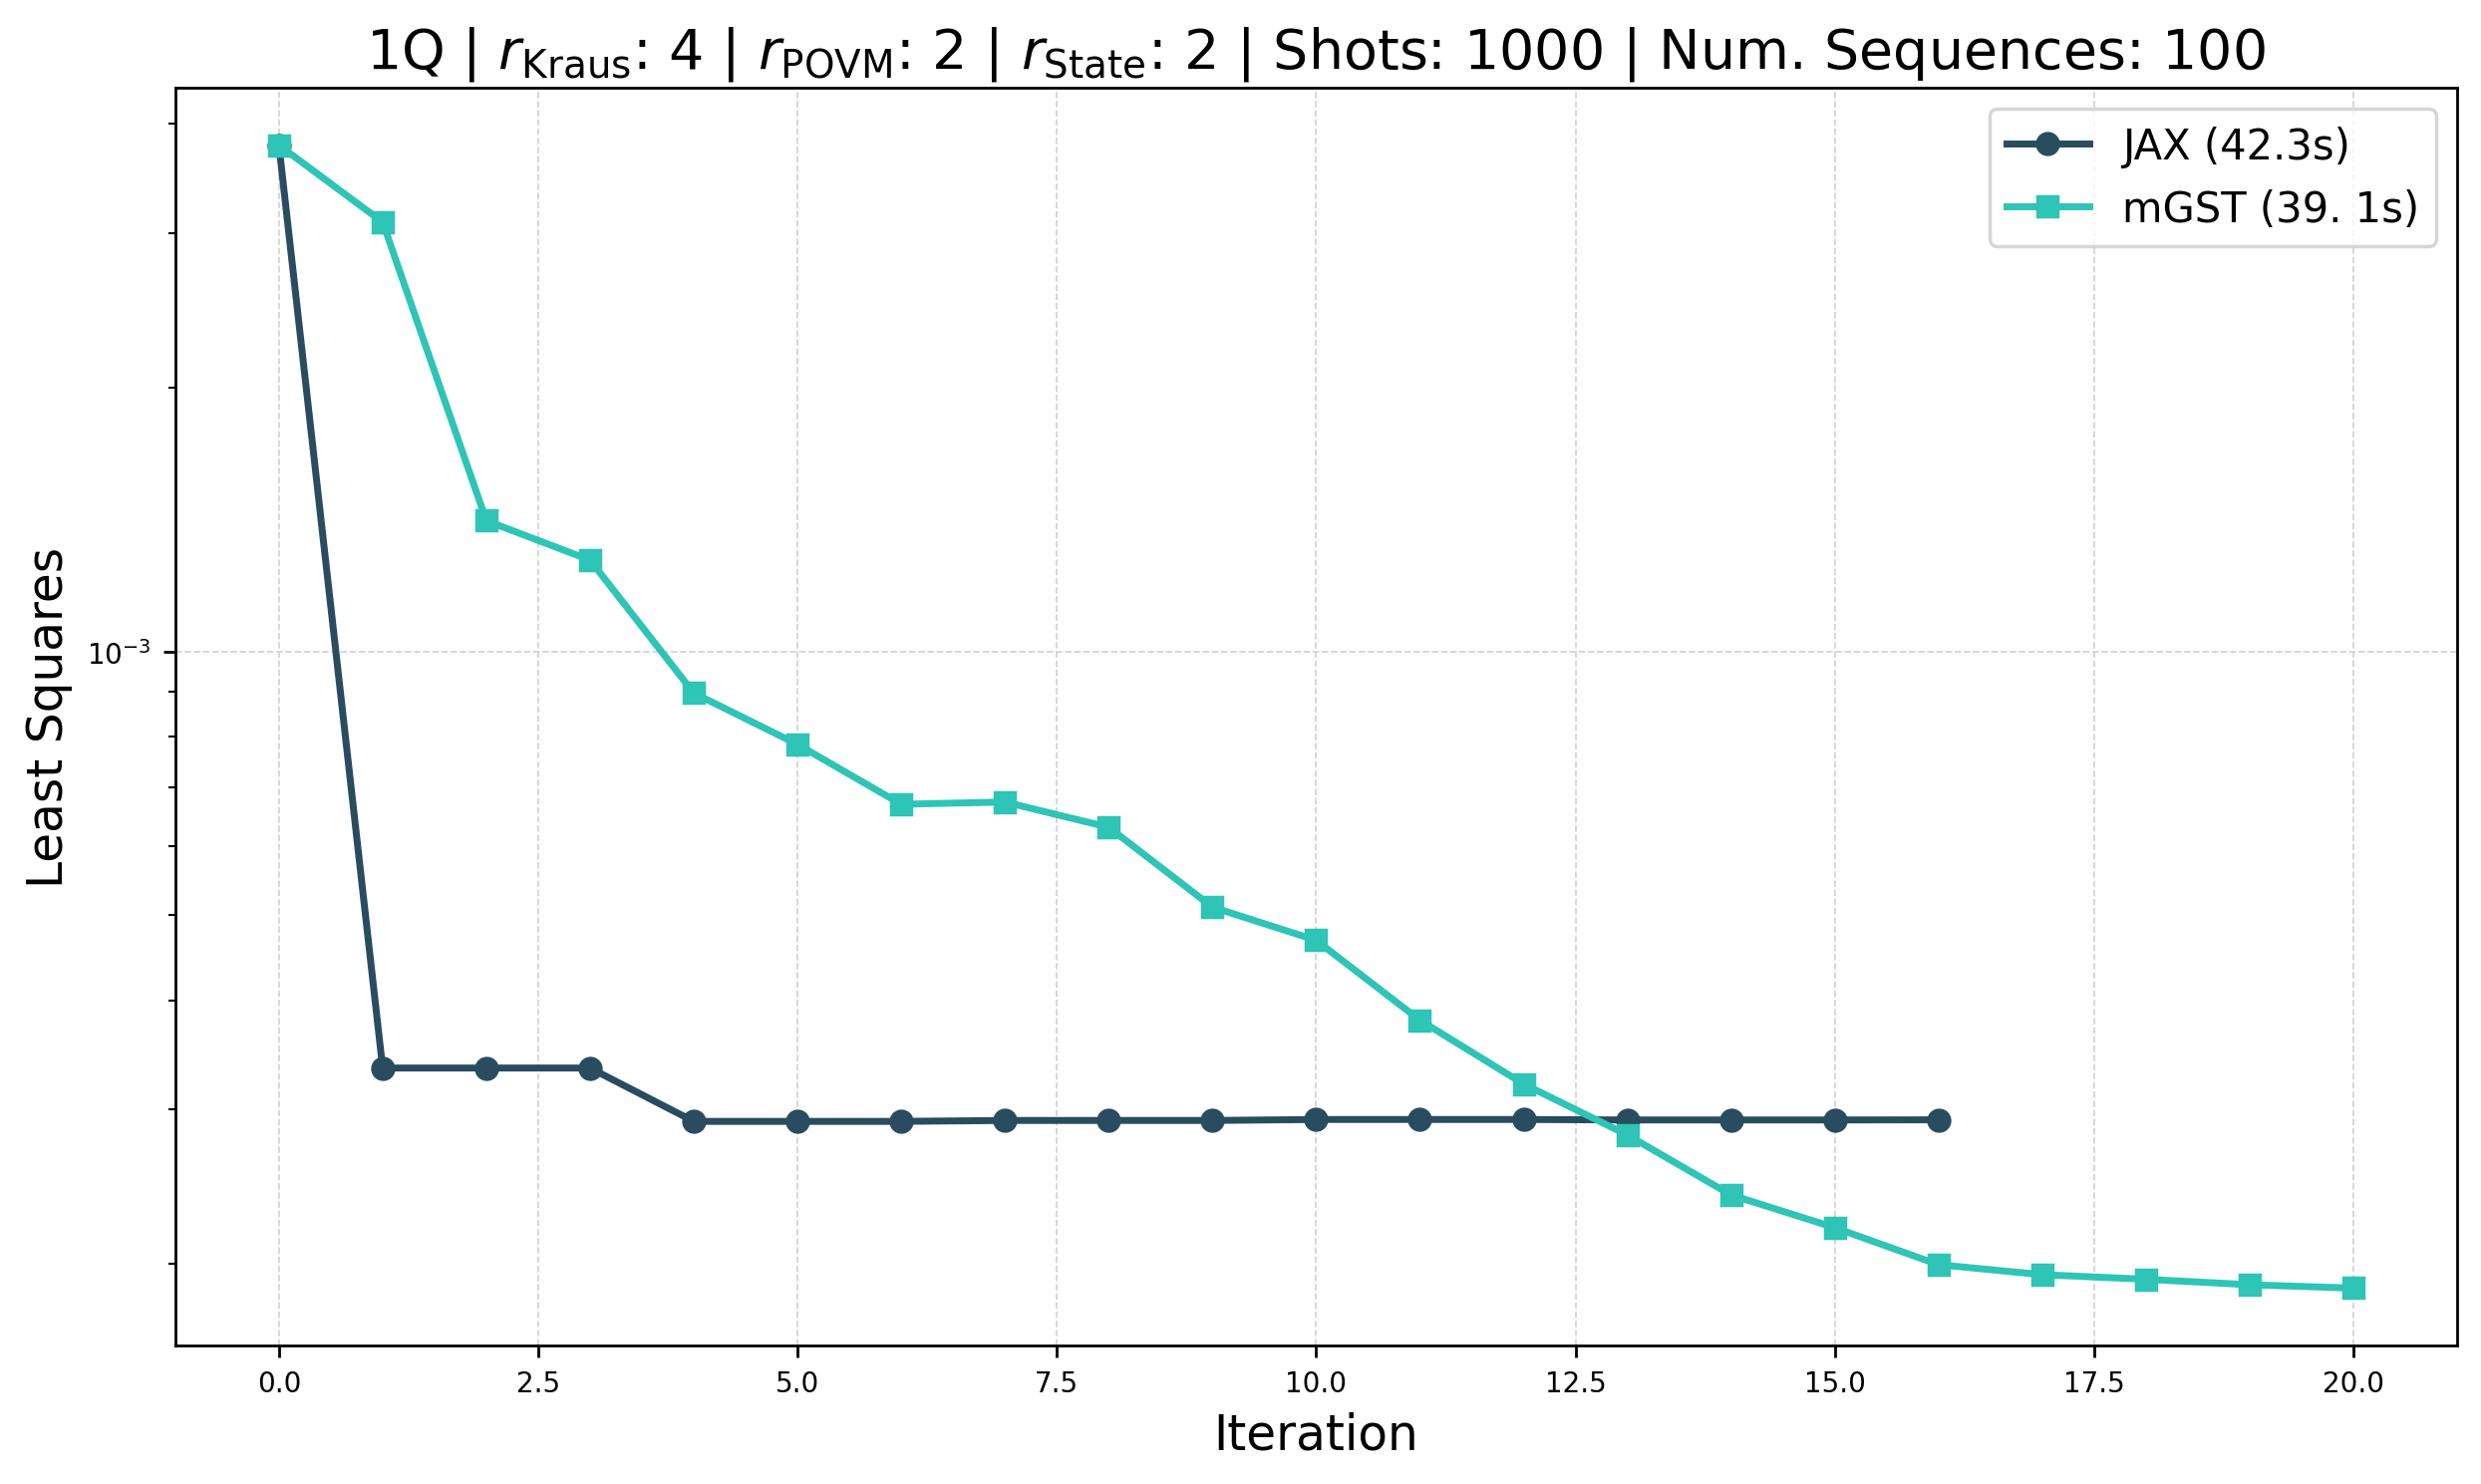

In [ ]:
# cost_fns_least_squares= [cost["least_squares"] for cost in cost_fns]
# plot_cost_function(cost_fns_least_squares, title=title_init, labels=labels, ylabel="Least Squares")

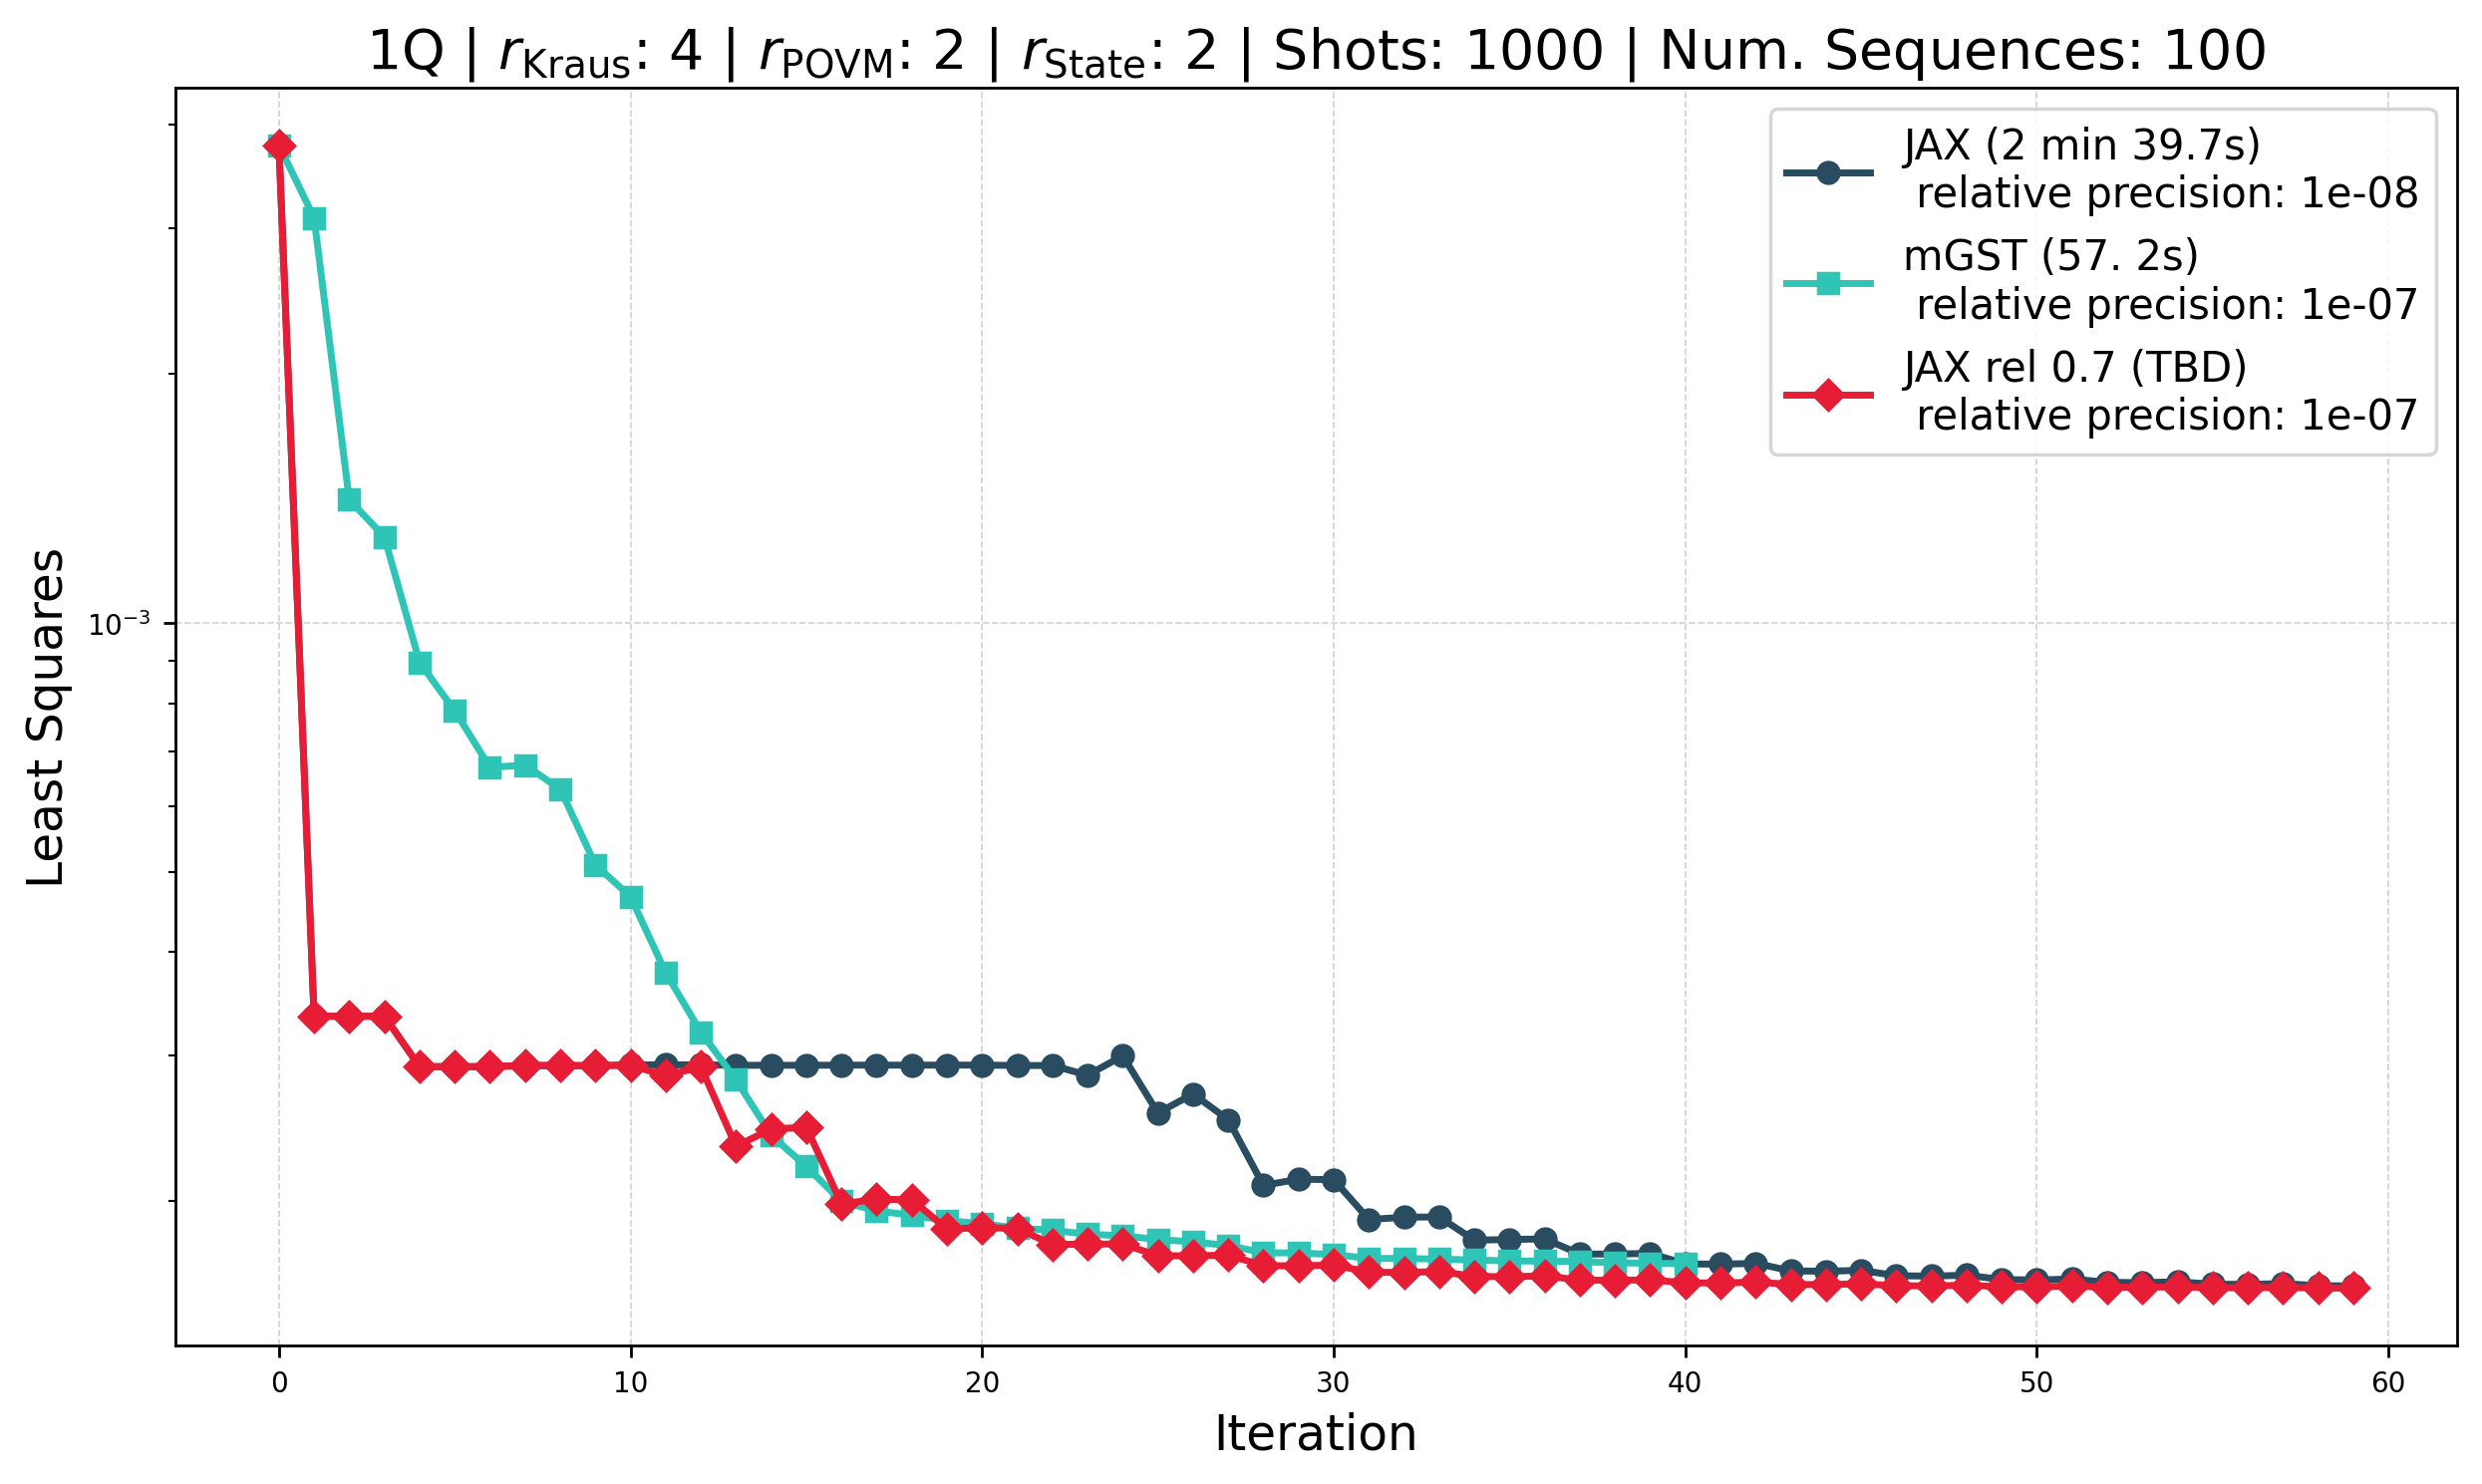

In [150]:
cost_fns_least_squares= [cost["least_squares"] for cost in cost_fns]
plot_cost_function(cost_fns_least_squares, title=title_init, labels=labels, ylabel="Least Squares")

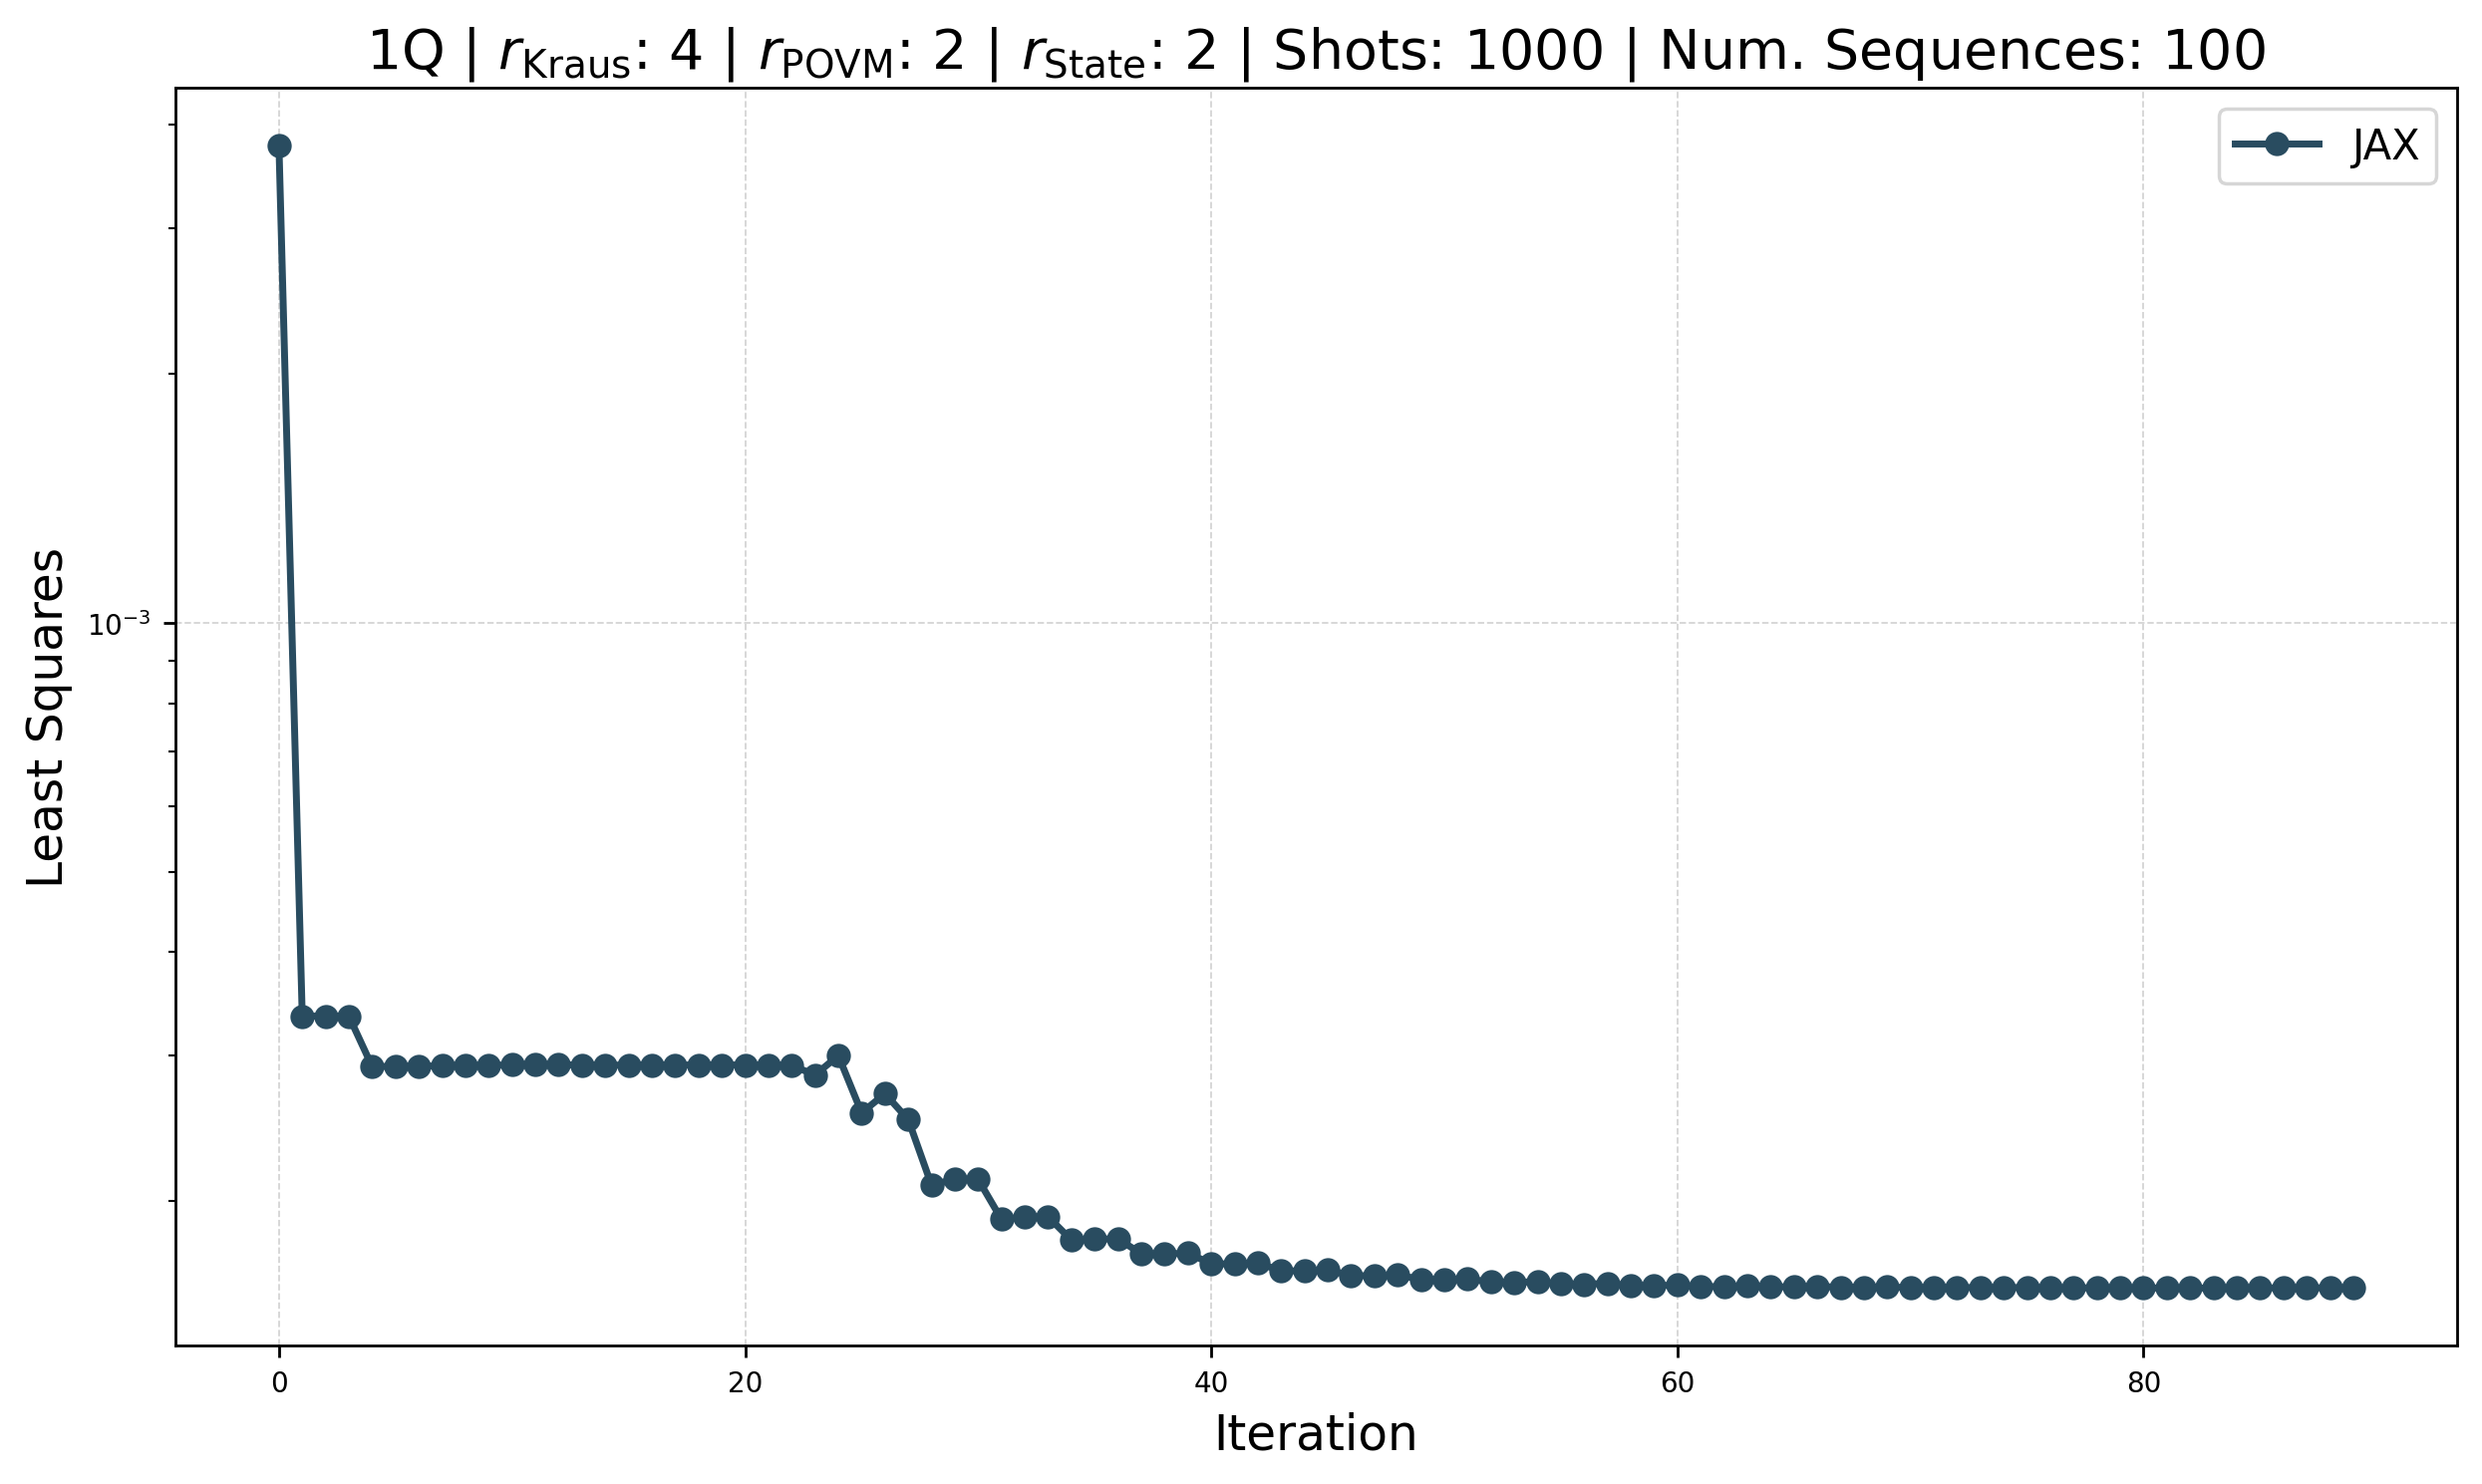

In [37]:
cost_fns_least_squares= [cost["least_squares"] for cost in cost_fns]
plot_cost_function(cost_fns_least_squares, title=title_init, labels=labels, ylabel="Least Squares")

In [121]:
jax_least_squares_init = cost_fns_least_squares[0][0]
mgst_least_squares_init = cost_fns_least_squares[1][0]
print(f"are they the same? {jnp.allclose(jax_least_squares_init, mgst_least_squares_init)}")

are they the same? True


In [122]:
final_value = cost_fn_history_jax["least_squares"][-1]
previous_value = cost_fn_history_jax["least_squares"][-2]
relative_change = jnp.abs(final_value - previous_value)
relative_change/previous_value,  relative_precision

(Array(0.00049752, dtype=float64), 1e-08)

In [42]:
# super long optimization with 1e-11 relative precision up to 80 iterations.
# final_value = cost_fn_history_jax["least_squares"][-1]
# previous_value = cost_fn_history_jax["least_squares"][-2]
# relative_change = jnp.abs(final_value - previous_value)
# relative_change/previous_value,  relative_precision

(Array(5.84606257e-06, dtype=float64), 1e-09)

# Debugging

In [123]:
optimized_operators_jax_rel_07.keys()

dict_keys(['kraus', 'povm', 'state'])

In [133]:
from mGST.trust_region import compute_quality_quotient, retraction_first_order, riemannian_and_euclidean_gradient_fn, riemannian_metric_from_tensors, get_isometry_dimensions_from_tensor, truncated_conjugate_gradient, riemannian_hessian_vector_fn

operator_type = "povm"
metric = "euclidean"
verbose_cg = True
theta_cg = 1
kappa_cg = 1/10
# what is causing the NAN in the quality quotients of POVM and state
cost_fn_povm = lambda x: cost_function_jax_mps(
                kraus_tensor=optimized_operators_jax_rel_07["kraus"], povm_psd=x, state_psd=optimized_operators_jax_rel_07["state"], **cost_fn_kwargs)

retraction = lambda x, z: retraction_first_order(x, z, operator_type=operator_type)


rgrad_and_euclidean_fn = lambda x: riemannian_and_euclidean_gradient_fn(x=x, cost_fn=cost_fn_povm, operator_type=operator_type, metric=metric)

rhessian_vector_fn = lambda x, z: riemannian_hessian_vector_fn(x=x, tangent_vector=z, cost_fn=cost_fn_povm, operator_type=operator_type, metric=metric, return_tensor=True)

x_k = optimized_operators_jax_rel_07[operator_type]
radius_k = 9.77e-05

n, p = get_isometry_dimensions_from_tensor(x_k, operator_type=operator_type)

rgradient, euclidean_gradient_conjugated = rgrad_and_euclidean_fn(x_k)

norm_grad_init = jnp.sqrt(riemannian_metric_from_tensors(n=n, p=p, z1=rgradient, z2=rgradient, x=x_k, metric=metric))
norm_grad = norm_grad_init

cost_fn_povm(x_k), norm_grad

(Array(54327.05372279, dtype=float64), Array(787141.89414474, dtype=float64))

In [145]:
update_direction, on_boundary = truncated_conjugate_gradient(x=x_k, radius=radius_k,num_iterations=num_iterations_cg, rgradient=rgradient, metric=metric, n=n, p=p, rhessian_vector_fn=rhessian_vector_fn, verbose=verbose_cg, theta=theta_cg, kappa=kappa_cg)

# Retract the update direction to obtain the next iterate
x_next = retraction(x_k, update_direction)

TCG finished after: 1/10 iters. 
 Reason: Exceeded trust region boundary 📈.
---------------------------------------


In [139]:
update_direction

Array([[[nan+nanj, nan+nanj],
        [nan+nanj, nan+nanj]],

       [[nan+nanj, nan+nanj],
        [nan+nanj, nan+nanj]]], dtype=complex128)

In [135]:
quality_quotient, cost_fx_next = compute_quality_quotient(
                x=x_k,
                update_direction=update_direction,
                cost_function=cost_fn_povm,
                x_next=x_next,
                n=n,
                p=p,
                euclidean_gradient_conjugated=euclidean_gradient_conjugated,
                euclidean_hvp=None,
                )

quality_quotient, cost_fx_next

(Array(nan, dtype=float64), Array(nan, dtype=float64))

In [138]:
# nan. Why?
cost_fn_povm(x_k), cost_fn_povm(x_next), x_next

(Array(54327.05372279, dtype=float64),
 Array(nan, dtype=float64),
 Array([[[nan+nanj, nan+nanj],
         [nan+nanj, nan+nanj]],
 
        [[nan+nanj, nan+nanj],
         [nan+nanj, nan+nanj]]], dtype=complex128))